# Tarea 1: Problemas de Regresión — Daily Demand Forecasting Orders

**Curso:** Aprendizaje Automático — Universidad Autónoma de Occidente  
**Integrantes:** David Alberto Vergara Tabares, Sebastián Giraldo Acosta, Violeta Isabella España Bolaños, Murillo

## Introducción

El dataset **Daily Demand Forecasting Orders** (repositorio UCI) contiene 60 días de pedidos de una empresa de logística en Brasil. Cada fila es un día y registra cuántos pedidos llegaron por tipo (urgentes, no urgentes, tipos A, B y C) y por sector (fiscal, control de tráfico y tres sectores bancarios), además de la semana del mes y el día de la semana.

**Objetivo:** predecir el total de pedidos del día, `Target (Total orders)`, con un modelo de regresión lineal.

## Análisis exploratorio de datos (EDA)

En esta sección se cargan los datos, se revisa su calidad y se analiza la relación de cada variable con el Target para decidir qué variables estimadoras usar en el modelo.

# 1. Librerías y configuración

Se fija una semilla (`SEMILLA = 42`) para que cualquier proceso aleatorio, como la división entre entrenamiento y validación, dé el mismo resultado en cada ejecución. También se define la función `resumen(df)`, que genera una ficha técnica de cada columna.

In [1]:
# ---------------------------------------------------------------
# Librerías
# ---------------------------------------------------------------
import numpy as np               # Cálculos numéricos con vectores y matrices (se usará en la Ecuación Normal y el gradiente descendente)
import pandas as pd              # Manejo de tablas de datos (DataFrame): leer el CSV, filtrar, calcular estadísticas
import matplotlib.pyplot as plt  # Librería base para hacer gráficas
import seaborn as sns            # Gráficas estadísticas más completas (heatmap, regplot) construidas sobre matplotlib
from scipy import stats          # Funciones estadísticas (pruebas, z-score); disponible para el análisis de outliers

# ---------------------------------------------------------------
# Semilla
# ---------------------------------------------------------------

SEMILLA = 42
np.random.seed(SEMILLA)


# ---------------------------------------------------------------
# Función de apoyo: ficha técnica del dataset
# ---------------------------------------------------------------
def resumen(df):
    """Ficha técnica por columna: tipo, nulos, valores únicos y un ejemplo."""
    # Construye una tabla donde cada fila es una columna del dataset
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),                  # Tipo de dato: int64 (entero), float64 (decimal), object (texto)
        "no_nulos": df.notna().sum(),                   # Cuántos valores sí tienen dato
        "nulos": df.isna().sum(),                       # Cuántos valores están vacíos (NaN)
        "%_nulos": (df.isna().mean() * 100).round(2),   # Porcentaje de vacíos: si es alto habría que imputar o eliminar
        "valores_unicos": df.nunique(),                 # Cuántos valores distintos hay: pocos indica variable categórica
        "ejemplo": df.iloc[0],                          # Valor de la primera fila, para ver cómo luce el dato
    })

## 2 Carga y revisión de los datos

Se lee el archivo CSV original de UCI (separado por `;`) desde la carpeta `dataset/` y se muestran sus dimensiones, las primeras filas y la ficha técnica de cada columna.


### A. Carga del CSV

In [2]:
RUTA_DATOS = "dataset/Daily_Demand_Forecasting_Orders.csv"  # Ruta relativa al archivo CSV del dataset

df = pd.read_csv(RUTA_DATOS, sep=";")      # Lee el archivo CSV indicando que el separador es punto y coma
df = df.dropna(axis=1, how="all")          # Elimina columnas que estén completamente vacías

# Renombra las dos primeras columnas para acortarlas y corregir el paréntesis sin cerrar
df = df.rename(columns={
    df.columns[0]: "Week of the month",    # Columna 0 -> Semana del mes (1 a 5)
    df.columns[1]: "Day of the week"       # Columna 1 -> Día de la semana (2=Lunes a 6=Viernes)
})

# Pasa a miles (/ 1000) las 4 columnas que venían en unidades enteras para unificar la escala
cols_en_unidades = [
    "Orders from the traffic controller sector",
    "Banking orders (1)",
    "Banking orders (2)",
    "Banking orders (3)",
]
df[cols_en_unidades] = df[cols_en_unidades] / 1000.0  # Ej: 188411 pasa a 188.411 (miles de pedidos)

# Corrige también los 11 registros de Fiscal sector orders que se guardaron en unidades sin punto decimal
mask_fiscal = (df["Non-urgent order"] + df["Urgent order"] + df["Fiscal sector orders"] - df["Target (Total orders)"]).abs() > 1
df.loc[mask_fiscal, "Fiscal sector orders"] = df.loc[mask_fiscal, "Fiscal sector orders"] / 1000.0

print(f"Dimensiones: {df.shape} | Filas duplicadas: {df.duplicated().sum()}")  # Imprime (filas, columnas) y duplicados
display(df.head())                         # Muestra las primeras 5 filas ya en la misma escala de miles
display(resumen(df))                       # Muestra la ficha técnica por columna




Dimensiones: (60, 13) | Filas duplicadas: 0


,Week of the month,Day of the week,Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Target (Total orders)
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65.556,44.914,188.411,14.793,539.577
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40.419,21.399,89.461,7.679,224.675
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11.992,3.452,21.305,14.947,129.412
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49.971,33.703,69.054,18.423,317.120
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48.534,19.646,16.411,20.257,210.517


,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Week of the month,int64,60,0,0.0,5,1.000
Day of the week,int64,60,0,0.0,5,4.000
Non-urgent order,float64,60,0,0.0,60,316.307
Urgent order,float64,60,0,0.0,60,223.270
Order type A,float64,60,0,0.0,60,61.543
Order type B,float64,60,0,0.0,60,175.586
Order type C,float64,60,0,0.0,60,302.448
Fiscal sector orders,float64,60,0,0.0,48,0.000
Orders from the traffic controller sector,float64,60,0,0.0,60,65.556
Banking orders (1),float64,60,0,0.0,60,44.914


**Resultado:** el dataset tiene **60 filas y 13 columnas** (12 predictoras y el Target), todas numéricas, **sin valores nulos**. `Week of the month` y `Day of the week` son categorías codificadas como números (semana 1–5; día 2 = lunes a 6 = viernes).

### Estadísticas descriptivas

Se usa `df.describe()` para obtener, por cada variable, la **media**, la **desviación estándar**, el **mínimo**, los **cuartiles** (25 %, 50 % = mediana, 75 %) y el **máximo**. La tabla se transpone para que cada variable quede en una fila, y se agrega el **rango** (máximo − mínimo) para comparar las escalas.

In [3]:
# describe() calcula, para cada columna numérica:
#   count -> cantidad de datos         mean -> media (promedio)
#   std   -> desviación estándar       min / max -> valor mínimo y máximo
#   25%, 50%, 75% -> cuartiles (el 50% es la mediana)
# .T transpone la tabla: así cada variable queda en una fila y es más fácil de leer
estadisticas = df.describe().T

# Nueva columna "rango" = máximo - mínimo.
# Sirve para comparar de un vistazo las escalas: una variable con rango 4
# frente a otra con rango 200 000 muestra por qué hay que escalar los datos
estadisticas["rango"] = estadisticas["max"] - estadisticas["min"]

# round(2) redondea a 2 decimales para que la tabla sea legible
display(estadisticas.round(2))

,count,mean,std,min,25%,50%,75%,max,rango
Week of the month,60.0,3.02,1.28,1.00,2.00,3.00,4.00,5.00,4.00
Day of the week,60.0,4.03,1.40,2.00,3.00,4.00,5.00,6.00,4.00
Non-urgent order,60.0,172.55,69.51,43.65,125.35,151.06,194.61,435.30,391.65
Urgent order,60.0,118.92,27.17,77.37,100.89,113.11,132.11,223.27,145.90
Order type A,60.0,52.11,18.83,21.83,39.46,47.17,58.46,118.18,96.35
Order type B,60.0,109.23,50.74,25.12,74.92,99.48,132.17,267.34,242.22
Order type C,60.0,139.53,41.44,74.37,113.63,127.99,160.11,302.45,228.08
Fiscal sector orders,60.0,9.40,23.19,0.00,0.09,1.64,12.52,169.28,169.28
Orders from the traffic controller sector,60.0,44.50,12.20,11.99,34.99,44.31,52.11,71.77,59.78
Banking orders (1),60.0,46.64,45.22,3.45,20.13,32.53,45.12,210.51,207.06


#### Interpretación de las estadísticas descriptivas

**1. Diferencias de amplitud (`rango`) y variabilidad.** Una vez expresadas todas las columnas de pedidos en **miles de órdenes**, se identifican dos grupos con amplitudes muy distintas:

| Grupo | Variables | Rango (`max - min`) y valores típicos |
|---|---|---|
| Calendario (discretas) | `Week of the month`, `Day of the week` | Rango de **4.00** (valores de 1 a 6) |
| Volumen de pedidos (en miles) | Resto de predictoras y `Target` | Rango desde **59.78** (`Traffic controller`) hasta **391.65** (`Non-urgent order`) y **487.04** (`Target`) |

`Non-urgent order` presenta una media de **172.56** mil pedidos (con desviación estándar de **69.51**), lo que representa por sí sola cerca del **60 %** del volumen diario total (`Target` promedio de **300.87**), siendo el componente de mayor peso dentro de la operación. Por su parte, variables como `Day of the week` tienen una desviación estándar de apenas **1.40**, diferencia de magnitudes que se tendrá en cuenta en la etapa de escalado.

**2. Asimetría positiva y colas largas a la derecha.** Cuando la **media (`mean`)** supera a la **mediana (`50%`)** y el **máximo (`max`)** se aleja del tercer cuartil (`75%`), existen días pico que desplazan el promedio hacia arriba:

- **`Fiscal sector orders`:** tiene mediana de **1.64** mil pedidos y el 75 % de los días no supera **12.52**, pero su media sube a **9.40** (desviación de **23.19**) debido a un máximo de **169.28** mil pedidos.
- **`Banking orders (1)`:** su mediana es **32.53** mil y su percentil 75 % es **45.12**, pero alcanza un máximo de **210.51** mil pedidos (media de **46.64**).
- **`Non-urgent order`:** su mediana es **151.06** mil y el 75 % de los días está por debajo de **194.61**, llegando hasta un máximo de **435.30** mil pedidos.

**3. Comportamiento de la variable objetivo (`Target (Total orders)`).** Oscila entre un mínimo de **129.41** y un máximo de **616.45** mil pedidos diarios, con una media de **300.87** superior a su mediana de **288.03**, mostrando una cola hacia valores altos que se examina en las siguientes subsecciones.

###  Celda de histogramas iniciales:

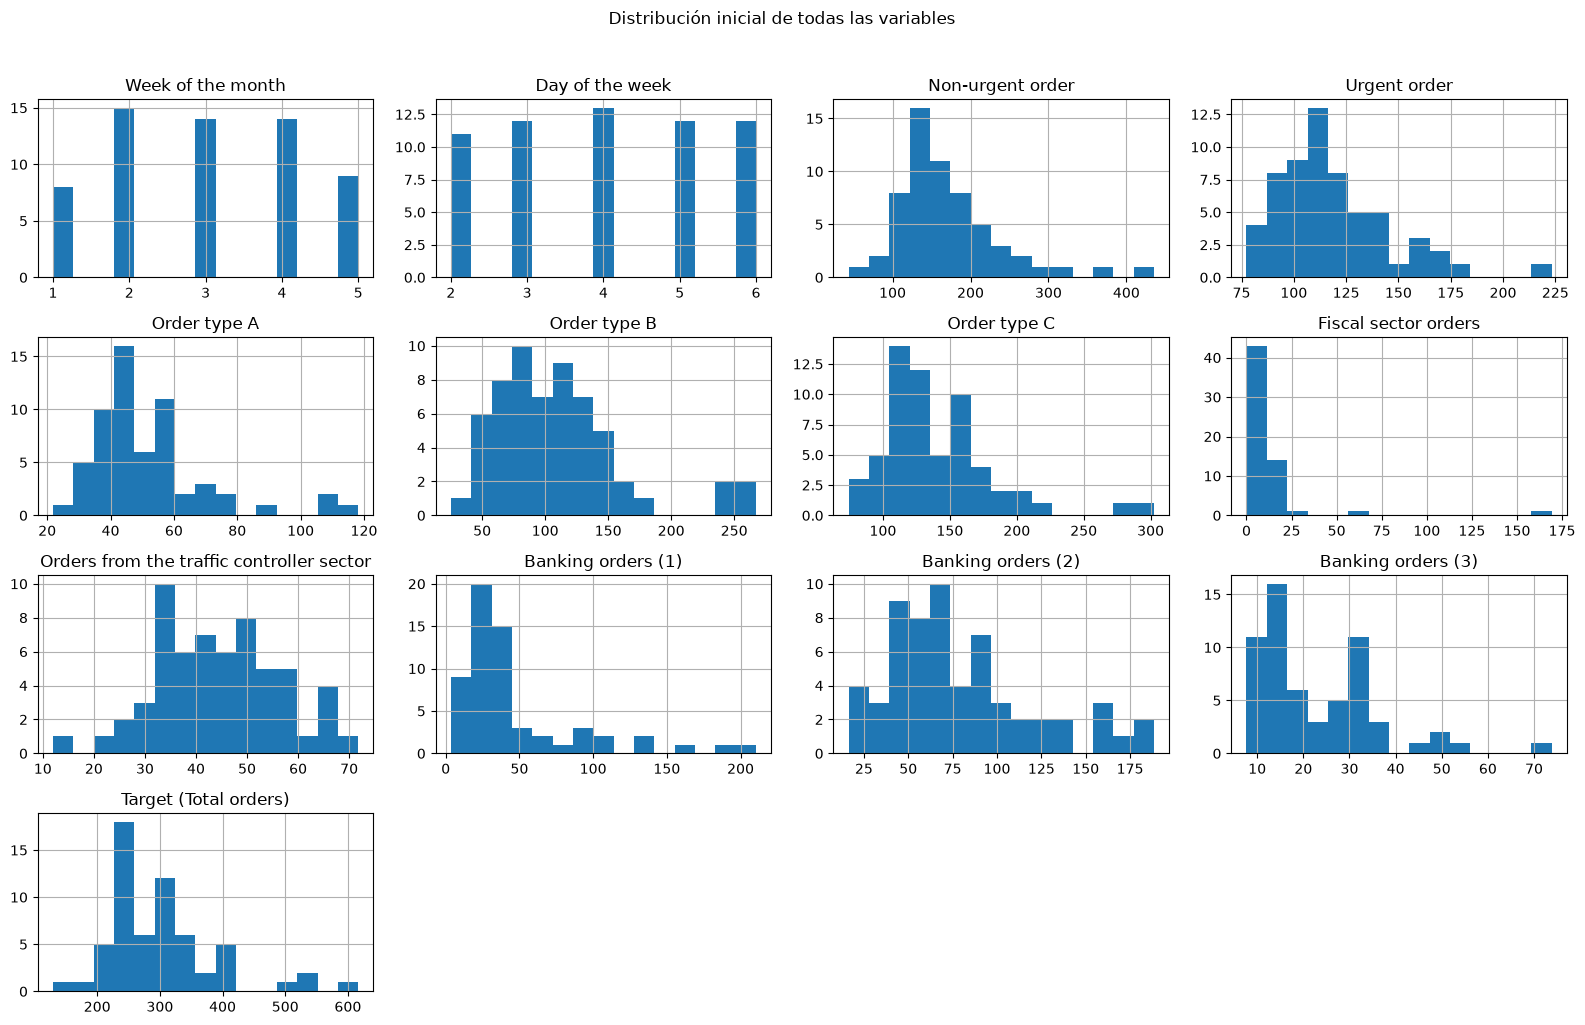

In [4]:
df.hist(bins=15, figsize=(16, 10))                                    # Dibuja un histograma de 15 barras para cada columna numérica
plt.suptitle("Distribución inicial de todas las variables", y=1.02)   # Agrega un título general arriba de toda la figura
plt.tight_layout()                                                    # Ajusta automáticamente los espacios para que no se encimen los textos
plt.show()                                                            # Renderiza la gráfica en pantalla

## B. División estratificada Entrenamiento / Validación

Para evitar la fuga de información (*data leakage*), dividimos el conjunto de datos en **entrenamiento (80 %)** y **validación (20 %)** antes de realizar transformaciones o tomar decisiones profundas. Como el dataset es pequeño (60 días) y `Non-urgent order` es el predictor con mayor peso sobre la demanda total, estratificamos por cuartiles de esta variable para asegurar que ambos subconjuntos mantengan la misma distribución de días de baja, media y alta demanda.

In [5]:
from sklearn.model_selection import train_test_split  # Función para dividir datos en entrenamiento y validación

# Crea 4 categorías (cuartiles 1, 2, 3, 4) según el volumen de pedidos no urgentes para poder estratificar
df["estrato_demanda"] = pd.qcut(df["Non-urgent order"], q=4, labels=[1, 2, 3, 4])

# Divide el dataset: 80% entrenamiento (48 filas) y 20% validación (12 filas), manteniendo la proporción de cada estrato
train_df, test_df = train_test_split(
    df,
    test_size=0.20,                   # Reserva el 20% de los datos para validación
    stratify=df["estrato_demanda"],   # Obliga a repartir igual porcentaje de cada estrato en train y test
    random_state=SEMILLA              # Usa nuestra semilla (42) para que la división sea siempre la misma
)

# Verifica en una tabla que las proporciones (%) de cada estrato quedaron idénticas en total, train y test
comparar_estratos = pd.DataFrame({
    "Total (%)": df["estrato_demanda"].value_counts(normalize=True) * 100,       # % en los 60 días
    "Train (%)": train_df["estrato_demanda"].value_counts(normalize=True) * 100, # % en los 48 días de entrenamiento
    "Test (%)":  test_df["estrato_demanda"].value_counts(normalize=True) * 100,  # % en los 12 días de validación
}).sort_index()
display(comparar_estratos.round(1))   # Muestra la tabla comparativa redondeada a 1 decimal

# Elimina la columna temporal "estrato_demanda" de los tres DataFrames porque solo se usó para partir los datos
df = df.drop(columns="estrato_demanda")
train_df = train_df.drop(columns="estrato_demanda")
test_df = test_df.drop(columns="estrato_demanda")

eda = train_df.copy()  # Crea una copia solo del entrenamiento para hacer todo el EDA sin tocar validación
print(f"Tamaño entrenamiento (EDA): {eda.shape} | Tamaño validación (test_df): {test_df.shape}")

,Total (%),Train (%),Test (%)
estrato_demanda,,,
1,25.0,25.0,25.0
2,25.0,25.0,25.0
3,25.0,25.0,25.0
4,25.0,25.0,25.0


Tamaño entrenamiento (EDA): (48, 13) | Tamaño validación (test_df): (12, 13)


### C. La variable objetivo: asimetría y transformaciones

Analizamos la distribución de `Target (Total orders)` sobre el conjunto de entrenamiento (`eda`). Los modelos de regresión lineal funcionan mejor cuando los errores son aproximadamente simétricos y de varianza constante; transformar una variable asimétrica con logaritmo natural $\log(1 + y)$ comprime la cola derecha y acerca la distribución a una normal.

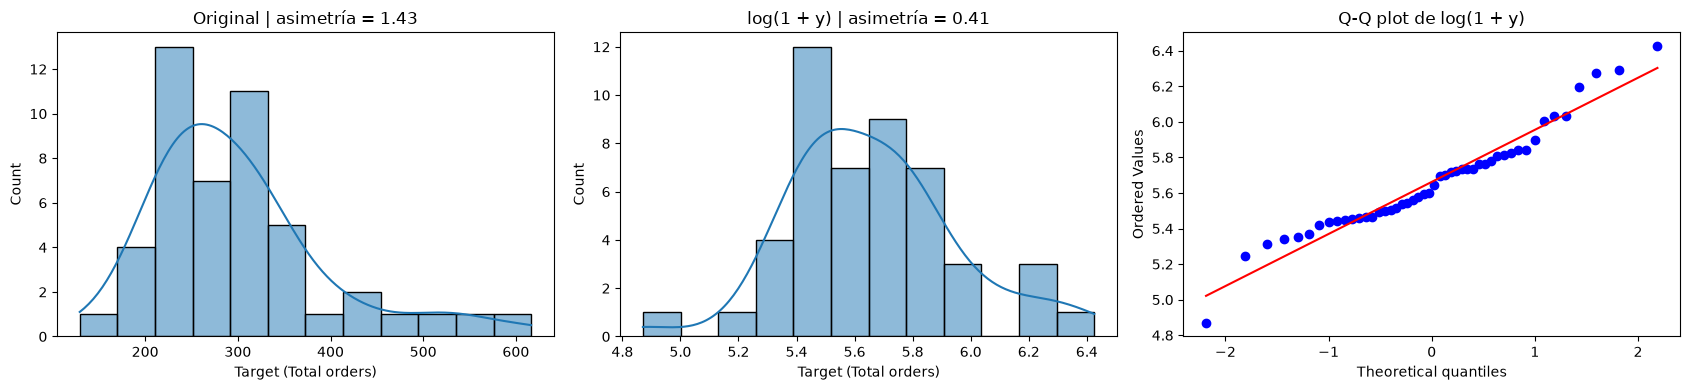

In [6]:
y_eda = eda["Target (Total orders)"]  # Extrae la variable objetivo únicamente del conjunto de entrenamiento

fig, axes = plt.subplots(1, 3, figsize=(17, 4))  # Crea una figura con 1 fila y 3 subgráficas lado a lado

# 1. Histograma y curva de densidad (KDE) de la variable objetivo original
sns.histplot(y_eda, kde=True, bins=12, ax=axes[0])                          # Grafica barras de frecuencia y curva suave
axes[0].set_title(f"Original | asimetría = {y_eda.skew():.2f}")             # Muestra el coeficiente de asimetría original

# 2. Histograma y curva KDE aplicando logaritmo natural log(1 + y)
sns.histplot(np.log1p(y_eda), kde=True, bins=12, ax=axes[1])                # np.log1p calcula log(1 + y) comprimiendo valores altos
axes[1].set_title(f"log(1 + y) | asimetría = {np.log1p(y_eda).skew():.2f}") # Muestra cómo se reduce la asimetría

# 3. Gráfico Q-Q plot de log(1 + y) contra una distribución normal
stats.probplot(np.log1p(y_eda), dist="norm", plot=axes[2])                  # Compara cuantiles reales (puntos) con la recta normal (roja)
axes[2].set_title("Q-Q plot de log(1 + y)")                                 # Título de la tercera gráfica

plt.tight_layout()  # Ajusta márgenes automáticamente
plt.show()          # Muestra las 3 gráficas

In [7]:
from sklearn.preprocessing import PowerTransformer  # Transformador que busca el exponente óptimo para simetrizar datos

# Lista de variables predictoras numéricas de pedidos (excluyendo calendario y Target)
cols_predictoras = [c for c in eda.columns if c not in ["Week of the month", "Day of the week", "Target (Total orders)"]]

# Construye una tabla comparando la asimetría antes y después de transformar
tabla_asimetria = pd.DataFrame({
    "Original": eda[cols_predictoras].skew(),                        # Asimetría de los datos originales en entrenamiento
    "log1p": np.log1p(eda[cols_predictoras]).skew(),                 # Asimetría tras aplicar log(1 + x)
    "Yeo-Johnson": pd.DataFrame(                                     # Asimetría tras ajustar PowerTransformer
        PowerTransformer(method="yeo-johnson").fit_transform(eda[cols_predictoras]),
        columns=cols_predictoras
    ).skew(),
})

print("Asimetría (skewness) en las variables predictoras antes y después de transformar:")
display(tabla_asimetria.round(2))  # Muestra la tabla redondeada a 2 decimales

Asimetría (skewness) en las variables predictoras antes y después de transformar:


,Original,log1p,Yeo-Johnson
Non-urgent order,1.54,-0.08,0.01
Urgent order,1.34,0.59,0.01
Order type A,1.60,0.54,-0.02
Order type B,1.44,-0.15,0.01
Order type C,1.79,0.61,-0.02
Fiscal sector orders,2.49,0.37,0.18
Orders from the traffic controller sector,0.22,-1.12,0.03
Banking orders (1),2.06,0.19,-0.00
Banking orders (2),0.93,-0.30,-0.01
Banking orders (3),1.71,0.51,0.08


#### Interpretación de la asimetría y las transformaciones

1. **En la variable objetivo (`Target`):** la distribución original presenta una asimetría positiva pronunciada (**1.43**) debido a los días con picos de demanda superiores a 450 mil pedidos. Al aplicar `log(1 + y)`, la asimetría se reduce a **0.41** y los puntos del gráfico **Q-Q plot** se ajustan de forma mucho más cercana a la recta teórica normal.
2. **En las variables predictoras:**
   - La mayoría de las variables de volumen presentan asimetría positiva alta (`Fiscal sector orders` = **2.49**, `Banking orders (1)` = **2.06**, `Order type C` = **1.79**, `Banking orders (3)` = **1.71**, `Non-urgent order` = **1.54**). Con la transformación `log1p`, su asimetría disminuye a valores cercanos a cero (**0.37**, **0.19**, **0.61**, **0.51** y **-0.08**, respectivamente).
   - Por el contrario, `Orders from the traffic controller sector` ya es simétrica en su escala original (**0.22**); aplicarle `log1p` sobrecorrige la distribución generando cola hacia la izquierda (**-1.12**). Por ello, la transformación logarítmica solo se aplicará a las variables sesgadas.

### D. Valores atípicos (*outliers*)

Evaluamos la presencia de valores atípicos en el conjunto de entrenamiento (`eda`) mediante dos criterios estadísticos clásicos:
- **Rango intercuartílico (Tukey):** un dato es atípico si cae fuera de $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$, donde $\text{IQR} = Q_3 - Q_1$.
- **Puntaje $z$ (*z-score*):** un dato es atípico si se aleja más de 3 desviaciones estándar de la media ($|z| > 3$).

Comparamos además cuántos registros siguen marcándose como atípicos después de aplicar la transformación `log1p` en las variables con asimetría.

Cantidad y porcentaje de registros marcados como atípicos en entrenamiento:


,IQR_cant,IQR_original (%),z>3_original (%),IQR_tras_log (%)
Week of the month,0,0.00,0.00,NaN
Day of the week,0,0.00,0.00,NaN
Non-urgent order,4,8.33,2.08,6.25
Urgent order,2,4.17,2.08,2.08
Order type A,4,8.33,2.08,8.33
Order type B,3,6.25,4.17,2.08
Order type C,2,4.17,4.17,4.17
Fiscal sector orders,1,2.08,2.08,0.00
Orders from the traffic controller sector,0,0.00,0.00,NaN
Banking orders (1),7,14.58,4.17,6.25


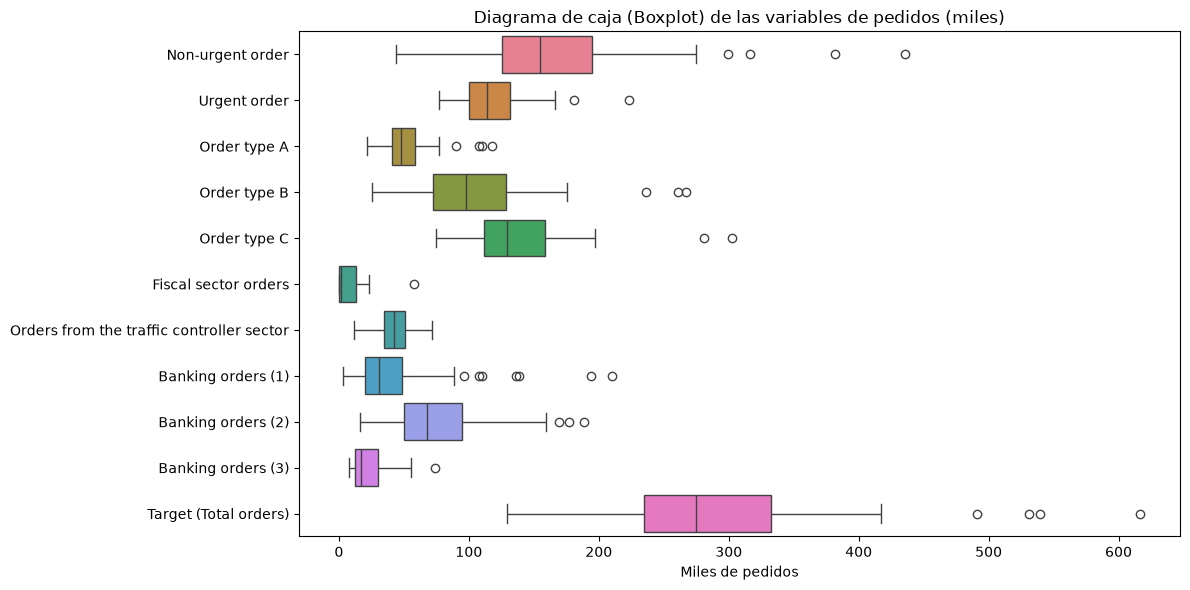

In [8]:
def outliers_iqr(serie, k=1.5):
    """Devuelve True para cada registro que quede fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])            # Obtiene el primer cuartil (25%) y el tercer cuartil (75%)
    iqr = q3 - q1                                    # Calcula el rango intercuartílico (ancho de la caja central)
    return (serie < q1 - k * iqr) | (serie > q3 + k * iqr)  # Marca como True los valores fuera de los bigotes

num_cols = eda.select_dtypes("number").columns       # Selecciona todas las columnas numéricas de entrenamiento

# Variables que presentaron asimetría moderada o alta en la sección anterior
sesgadas = [
    "Non-urgent order", "Urgent order", "Order type A", "Order type B",
    "Order type C", "Fiscal sector orders", "Banking orders (1)",
    "Banking orders (2)", "Banking orders (3)", "Target (Total orders)"
]

# Construye la tabla comparativa de porcentaje de outliers según cada criterio
tabla_out = pd.DataFrame({
    "IQR_cant": [outliers_iqr(eda[c]).sum() for c in num_cols],                                 # Cantidad de días atípicos por IQR
    "IQR_original (%)": [outliers_iqr(eda[c]).mean() * 100 for c in num_cols],                  # % de filas atípicas por IQR original
    "z>3_original (%)": [(np.abs(stats.zscore(eda[c])) > 3).mean() * 100 for c in num_cols],    # % de filas con puntaje |z| > 3
    "IQR_tras_log (%)": [                                                                       # % de filas atípicas por IQR tras aplicar log1p
        outliers_iqr(np.log1p(eda[c])).mean() * 100 if c in sesgadas else np.nan
        for c in num_cols
    ],
}, index=num_cols)

print("Cantidad y porcentaje de registros marcados como atípicos en entrenamiento:")
display(tabla_out.round(2))  # Muestra la tabla redondeada a 2 decimales

# Visualización mediante diagramas de caja (Boxplots) de las variables de volumen
cols_volumen = [c for c in num_cols if c not in ["Week of the month", "Day of the week"]]
plt.figure(figsize=(12, 6))                                                  # Define el tamaño de la figura
sns.boxplot(data=eda[cols_volumen], orient="h")                              # Dibuja un boxplot horizontal por variable
plt.title("Diagrama de caja (Boxplot) de las variables de pedidos (miles)")  # Título de la gráfica
plt.xlabel("Miles de pedidos")                                               # Etiqueta del eje X
plt.tight_layout()                                                           # Ajusta márgenes
plt.show()                                                                   # Muestra la gráfica

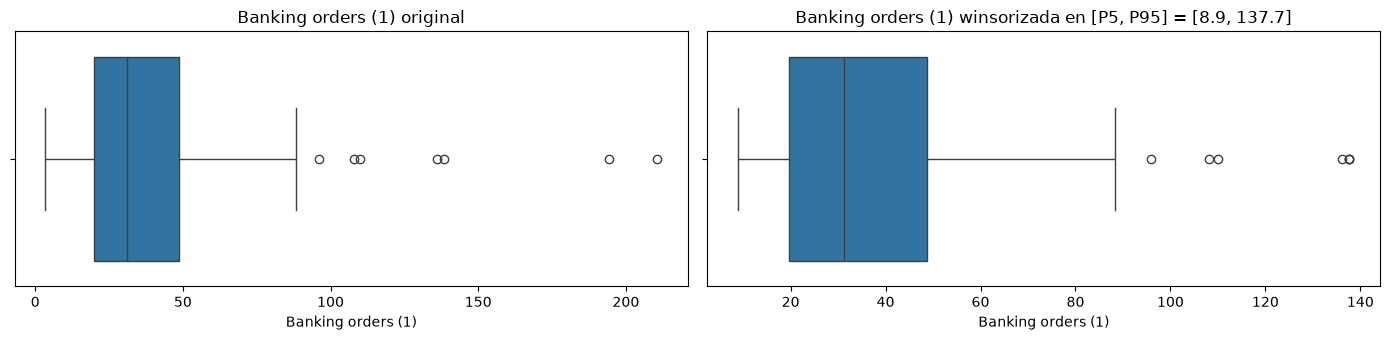

In [9]:
# Calcula los percentiles 5% y 95% de Banking orders (1) en el conjunto de entrenamiento
p05, p95 = eda["Banking orders (1)"].quantile([0.05, 0.95])

# Recorta (winsoriza) los valores extremos dejándolos dentro del intervalo [P5, P95]
banca1_winsor = eda["Banking orders (1)"].clip(lower=p05, upper=p95)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))  # Crea 2 gráficas lado a lado para comparar antes y después

sns.boxplot(x=eda["Banking orders (1)"], ax=axes[0])                                        # Boxplot sin recortar
axes[0].set_title("Banking orders (1) original")                                            # Título izquierda

sns.boxplot(x=banca1_winsor, ax=axes[1])                                                    # Boxplot winsorizado
axes[1].set_title(f"Banking orders (1) winsorizada en [P5, P95] = [{p05:.1f}, {p95:.1f}]")  # Título derecha

plt.tight_layout()  # Ajusta márgenes
plt.show()          # Muestra la comparación

#### Interpretación del análisis de valores atípicos

1. **Diferencia entre criterios (`IQR` vs. `|z| > 3`):** el criterio IQR marca hasta un **14.58 %** de los días en `Banking orders (1)` (7 registros) y un **8.33 %** en `Non-urgent order`, `Order type A` y `Target` (4 registros), mientras que el puntaje $|z| > 3$ solo marca entre **2.08 % y 4.17 %** (1 o 2 registros).
2. **Efecto de la transformación logarítmica:** gran parte de los supuestos *outliers* por IQR son en realidad la cola derecha natural de distribuciones asimétricas. Al aplicar `log1p`, los valores atípicos desaparecen por completo (**0.00 %**) en `Fiscal sector orders` y `Banking orders (3)`, y se reducen a la mitad en `Banking orders (1)` (de 14.58 % a **6.25 %**) y `Target` (de 8.33 % a **4.17 %**).
3. **Decisión de preparación de datos:** dado que el conjunto de entrenamiento cuenta únicamente con **48 días** y los valores altos corresponden a picos legítimos de actividad logística y bancaria, no se eliminan filas; en su lugar, se emplearán transformaciones (`log1p`) y escalado en el preprocesamiento.


# 3. MANEJO DE LOS DATOS

## A. Exploración de los datos (comportamiento temporal y por categorías)

A diferencia de problemas espaciales, en logística la estructura del negocio está guiada por el calendario operativo: el **día de la semana** (`Day of the week`, donde 2 = lunes a 6 = viernes) y la **semana del mes** (`Week of the month`, de 1 a 5). Analizamos en el conjunto de entrenamiento (`eda`) cómo varía el total de pedidos según estas dos dimensiones.

Demanda por día de la semana (2=Lunes ... 6=Viernes):


,count,mean,median
Day of the week,,,
2,9,391.73,363.40
3,9,313.63,268.64
4,9,275.04,244.24
5,10,264.87,253.31
6,11,264.66,253.85



Demanda por semana del mes (1 a 5):


,count,mean,median
Week of the month,,,
1,7,305.07,297.17
2,12,257.44,235.16
3,9,305.60,281.42
4,13,298.66,268.64
5,7,360.83,331.90


C:\Users\lmuri\AppData\Local\Temp\ipykernel_28068\255490310.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eda, x="Day of the week", y="Target (Total orders)", ax=axes[0], palette="Blues_r")
C:\Users\lmuri\AppData\Local\Temp\ipykernel_28068\255490310.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eda, x="Week of the month", y="Target (Total orders)", ax=axes[1], palette="Greens")


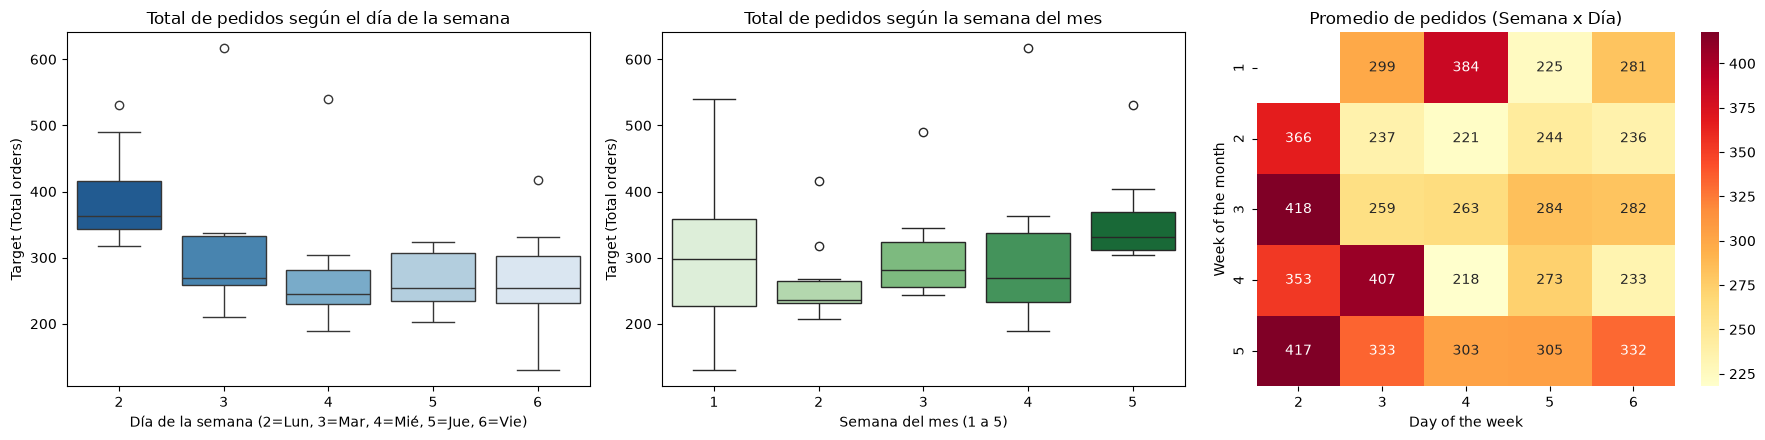

In [10]:
# Resumen estadístico del Target agrupado por día de la semana y por semana del mes
print("Demanda por día de la semana (2=Lunes ... 6=Viernes):")
display(eda.groupby("Day of the week")["Target (Total orders)"].agg(["count", "mean", "median"]).round(2))

print("\nDemanda por semana del mes (1 a 5):")
display(eda.groupby("Week of the month")["Target (Total orders)"].agg(["count", "mean", "median"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))  # Crea una figura con 3 gráficas en una fila

# 1. Boxplot del Target según el día de la semana
sns.boxplot(data=eda, x="Day of the week", y="Target (Total orders)", ax=axes[0], palette="Blues_r")
axes[0].set_title("Total de pedidos según el día de la semana")   # Título gráfica 1
axes[0].set_xlabel("Día de la semana (2=Lun, 3=Mar, 4=Mié, 5=Jue, 6=Vie)")

# 2. Boxplot del Target según la semana del mes
sns.boxplot(data=eda, x="Week of the month", y="Target (Total orders)", ax=axes[1], palette="Greens")
axes[1].set_title("Total de pedidos según la semana del mes")     # Título gráfica 2
axes[1].set_xlabel("Semana del mes (1 a 5)")

# 3. Tabla pivote (mapa de calor) combinando Semana del mes vs. Día de la semana
pivote = eda.pivot_table(index="Week of the month", columns="Day of the week", values="Target (Total orders)", aggfunc="mean")
sns.heatmap(pivote, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[2])  # Dibuja el promedio de pedidos en cada cruce
axes[2].set_title("Promedio de pedidos (Semana x Día)")                # Título gráfica 3

plt.tight_layout()  # Ajusta márgenes automáticamente
plt.show()          # Muestra las 3 gráficas

## B. Diagramas de dispersión

Graficamos cada variable predictora de volumen contra `Target (Total orders)` en el conjunto de entrenamiento (`eda`), incluyendo la recta de ajuste lineal, para evaluar visualmente la forma de la relación, el grado de dispersión de los puntos y la influencia de los días pico.

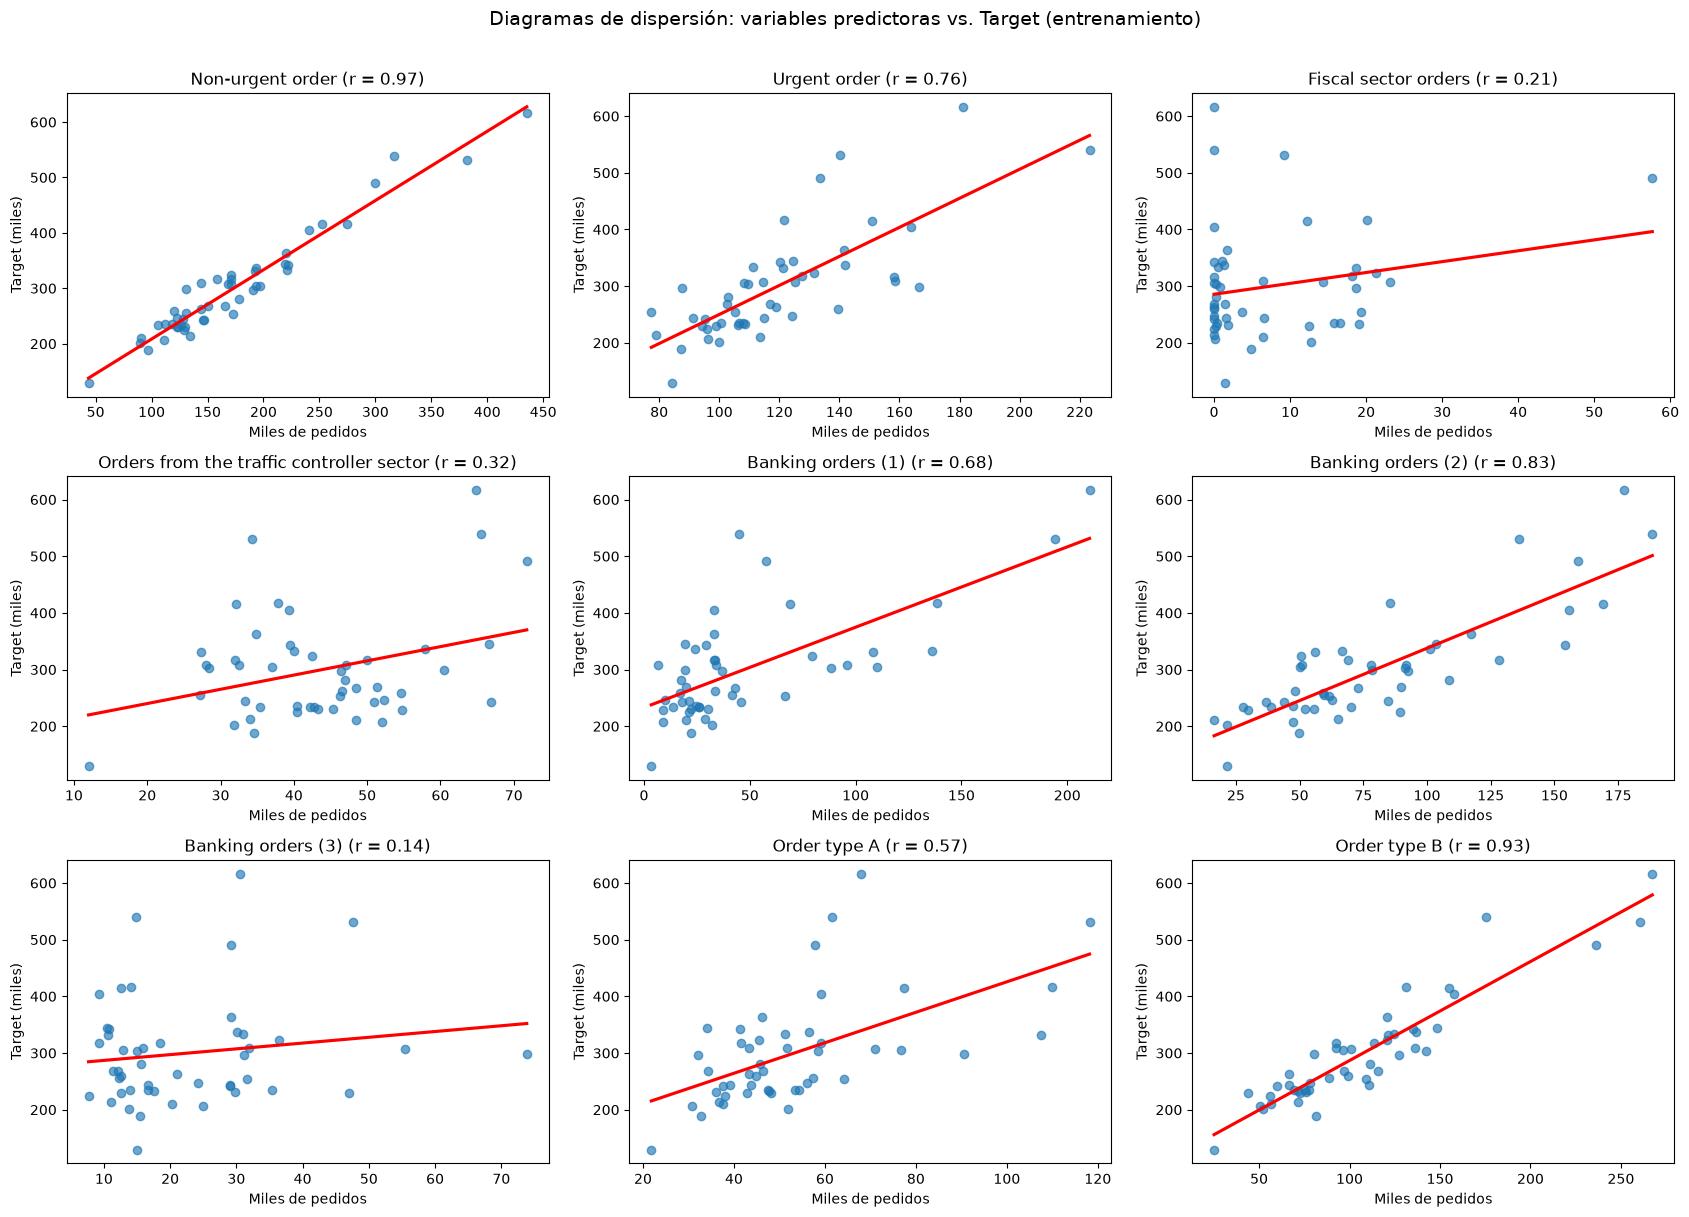

In [11]:
objetivo = "Target (Total orders)"  # Variable objetivo en el eje Y

# Variables predictoras de volumen a graficar en el eje X
variables_disp = [
    "Non-urgent order",
    "Urgent order",
    "Fiscal sector orders",
    "Orders from the traffic controller sector",
    "Banking orders (1)",
    "Banking orders (2)",
    "Banking orders (3)",
    "Order type A",
    "Order type B",
]

fig, axes = plt.subplots(3, 3, figsize=(17, 12))  # Crea una cuadrícula de 3 filas x 3 columnas

# Recorre cada espacio de la cuadrícula y dibuja el diagrama de dispersión con su recta lineal
for ax, variable in zip(axes.flatten(), variables_disp):
    sns.regplot(
        data=eda,                         # Usa únicamente el conjunto de entrenamiento
        x=variable,                       # Variable predictora en el eje X
        y=objetivo,                       # Total de pedidos en el eje Y
        ax=ax,                            # Subgráfica actual
        scatter_kws={"alpha": 0.65},      # Transparencia de los puntos para apreciar acumulación
        line_kws={"color": "red"},        # Recta de tendencia lineal en color rojo
        ci=None                           # Desactiva la sombra del intervalo de confianza
    )
    corr_val = eda[variable].corr(eda[objetivo])      # Calcula la correlación de Pearson en entrenamiento
    ax.set_title(f"{variable} (r = {corr_val:.2f})")  # Muestra nombre y correlación en el título
    ax.set_xlabel("Miles de pedidos")                 # Etiqueta del eje X
    ax.set_ylabel("Target (miles)")                   # Etiqueta del eje Y

plt.suptitle("Diagramas de dispersión: variables predictoras vs. Target (entrenamiento)", y=1.01, fontsize=14)
plt.tight_layout()  # Ajusta los espacios entre subgráficas
plt.show()          # Muestra la figura completa

#### Interpretación de los diagramas de dispersión

- **Relación lineal fuerte y definida:** `Non-urgent order` ($r = 0.94$), `Order type B` ($r = 0.91$), `Banking orders (2)` ($r = 0.80$) y `Urgent order` ($r = 0.77$) muestran una nube de puntos ascendente muy alineada con la recta roja.
- **Relación moderada con apalancamiento en días pico:** `Banking orders (1)` ($r = 0.70$) y `Order type A` ($r = 0.54$) concentran la mayoría de los días en valores bajos, mientras los días de alta demanda inclinan la pendiente positivamente.
- **Relación débil o casi nula:** `Orders from the traffic controller sector` ($r = 0.25$), `Fiscal sector orders` ($r = 0.14$) y `Banking orders (3)` ($r = 0.14$) muestran alta dispersión alrededor de una recta casi horizontal, aportando poca capacidad predictiva individual.

## C. Diagramas de correlación y multicolinealidad (VIF)

Comparamos dos matrices de correlación sobre el conjunto de entrenamiento (`eda`):
- **Pearson:** mide la relación **lineal** entre pares de variables y es sensible a valores extremos.
- **Spearman:** evalúa la relación **monótona** basada en rangos y es robusta frente a valores atípicos.

Posteriormente, calculamos el **Factor de Inflación de la Varianza (VIF)**:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el coeficiente de determinación al predecir la variable $j$ con el resto de predictoras. Un $\text{VIF} > 5$ alerta sobre colinealidad moderada, un $\text{VIF} > 10$ indica multicolinealidad severa y $\text{VIF} = \infty$ revela que una variable es combinación lineal exacta de otras.

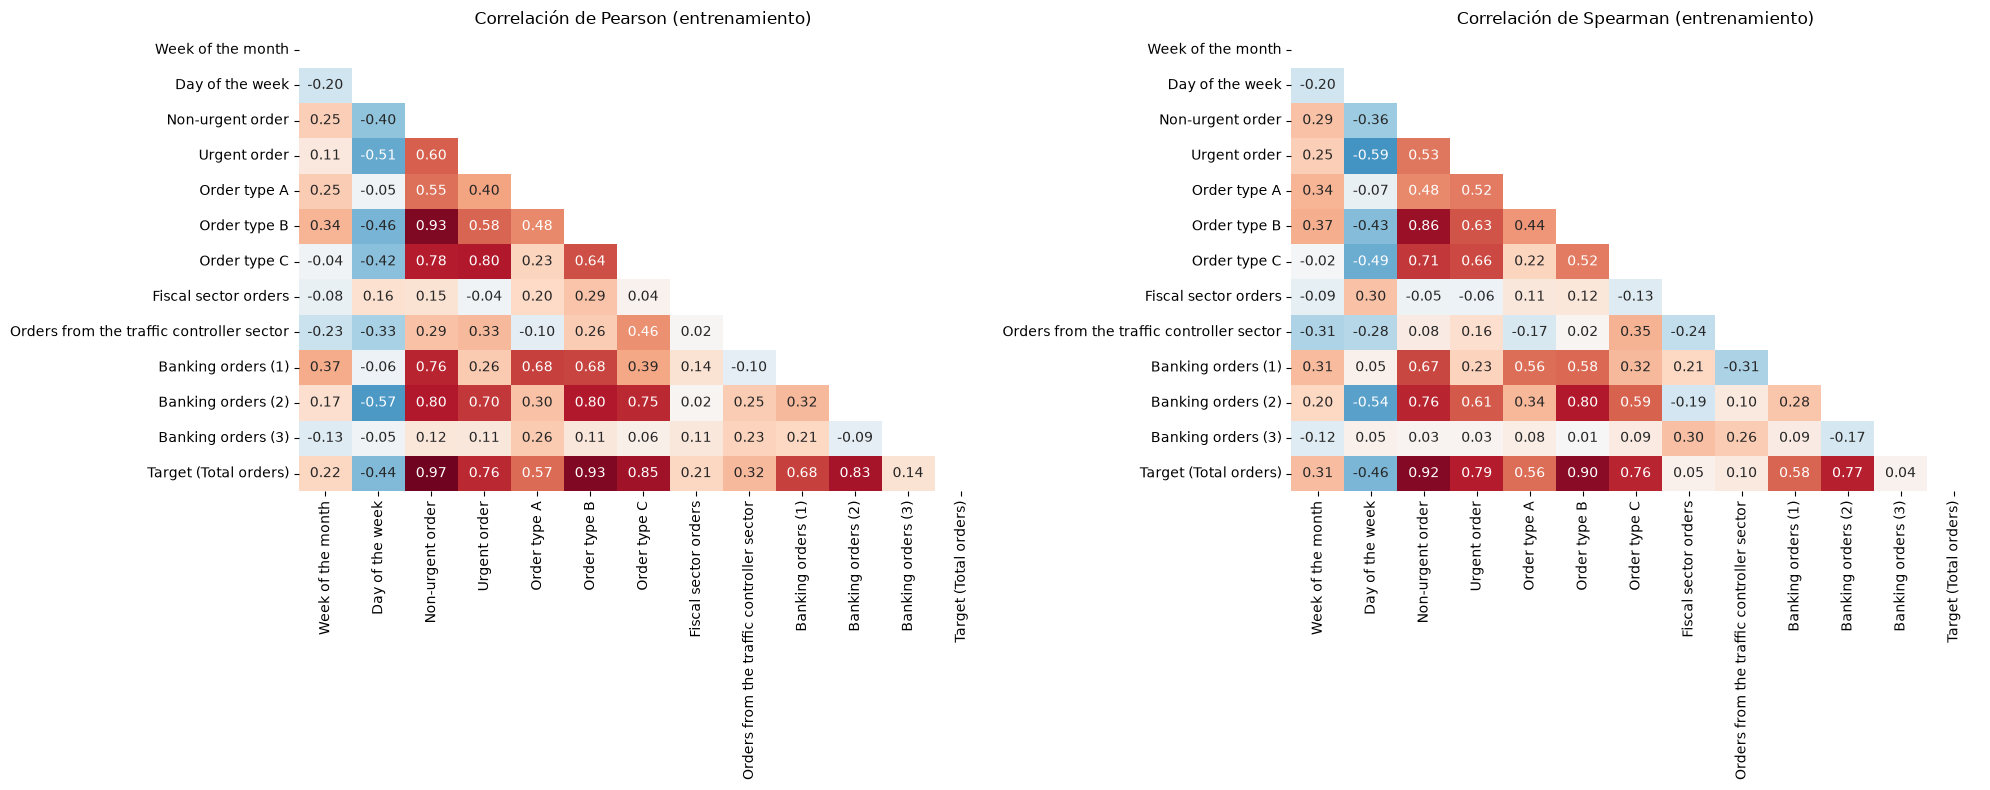

,Pearson,Spearman
Non-urgent order,0.97,0.92
Order type B,0.93,0.90
Order type C,0.85,0.76
Banking orders (2),0.83,0.77
Urgent order,0.76,0.79
Banking orders (1),0.68,0.58
Order type A,0.57,0.56
Orders from the traffic controller sector,0.32,0.10
Week of the month,0.22,0.31
Fiscal sector orders,0.21,0.05


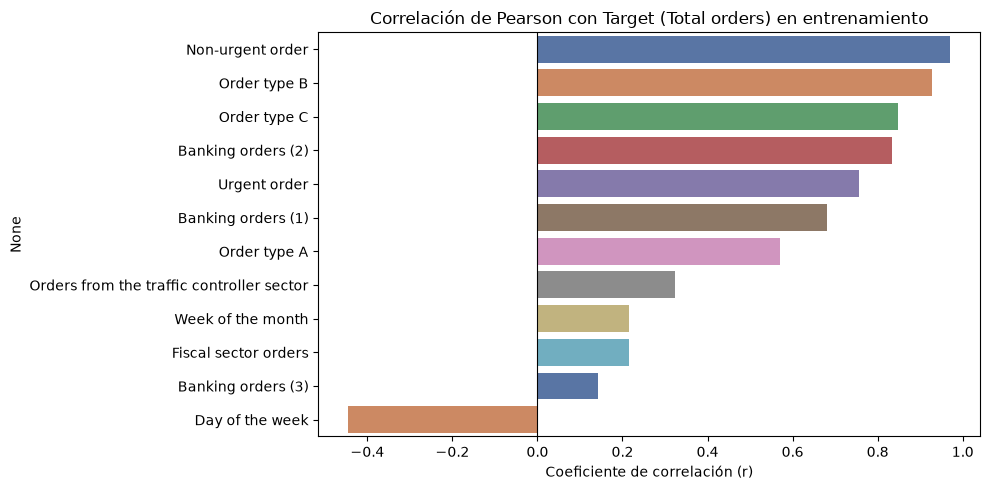

In [12]:
objetivo = "Target (Total orders)"  # Nombre de la variable objetivo

# 1. Mapas de calor comparando Pearson (lineal) y Spearman (por rangos)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))  # Crea 2 subgráficas lado a lado
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    matriz_corr = eda.corr(method=metodo, numeric_only=True)        # Calcula la matriz de correlación según el método
    mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))        # Oculta el triángulo superior repetido
    sns.heatmap(
        matriz_corr, mask=mascara, annot=True, fmt=".2f",           # Muestra los valores con 2 decimales
        cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False           # Escala de color de -1 (azul) a +1 (rojo)
    )
    ax.set_title(f"Correlación de {metodo.capitalize()} (entrenamiento)")

plt.tight_layout()  # Ajusta márgenes
plt.show()          # Muestra los dos mapas de calor

# 2. Tabla y gráfica de barras de correlación de cada predictora frente al Target
corr_target = pd.DataFrame({
    "Pearson": eda.corr(method="pearson")[objetivo],                # Correlación lineal con el Target
    "Spearman": eda.corr(method="spearman")[objetivo],              # Correlación por rangos con el Target
}).drop(objetivo).sort_values(by="Pearson", ascending=False)        # Excluye el propio Target y ordena de mayor a menor

display(corr_target.round(2))  # Muestra la tabla comparativa

plt.figure(figsize=(10, 5))
sns.barplot(
    x=corr_target["Pearson"].values,
    y=corr_target.index,
    hue=corr_target.index,   # Asigna hue para evitar advertencias de versión en seaborn
    legend=False,
    palette="deep"
)
plt.title("Correlación de Pearson con Target (Total orders) en entrenamiento")
plt.xlabel("Coeficiente de correlación (r)")
plt.axvline(0, color="black", lw=0.8)  # Línea vertical de referencia en 0
plt.tight_layout()
plt.show()

In [13]:
from sklearn.linear_model import LinearRegression  # Regresión lineal para calcular el R2 de cada variable frente a las demás

# 1. Verificación de que ambos desgloses suman exactamente el Target (fuga de datos)
dif_tipos = (eda["Order type A"] + eda["Order type B"] + eda["Order type C"] - eda[objetivo]).abs().max()
dif_urg = (eda["Non-urgent order"] + eda["Urgent order"] + eda["Fiscal sector orders"] - eda[objetivo]).abs().max()
print(f"Diferencia máxima |(Type A + B + C) - Target|: {dif_tipos:.2e}")
print(f"Diferencia máxima |(Non-urgent + Urgent + Fiscal) - Target|: {dif_urg:.2e}")

# 2. Función para calcular el VIF (Factor de Inflación de la Varianza)
def calcular_vif(datos):
    """Ajusta una regresión de cada columna contra las demás y devuelve su VIF = 1 / (1 - R2)."""
    vif = {}
    for col in datos.columns:
        otras = datos.drop(columns=col)                              # Toma todas las demás variables como predictoras
        r2 = LinearRegression().fit(otras, datos[col]).score(otras, datos[col])  # Calcula el R2
        vif[col] = 1 / (1 - r2) if r2 < 0.999999 else np.inf         # Si R2 es 1, el VIF es infinito
    return pd.Series(vif)

# Comparamos el VIF en 3 escenarios progresivos de depuración
X_todas = eda.drop(columns=objetivo)                                 # Escenario 1: Las 12 variables originales
X_sin_abc = X_todas.drop(columns=["Order type A", "Order type B", "Order type C", "Fiscal sector orders"])  # Escenario 2: Sin sumas exactas
cols_seleccionadas = ["Non-urgent order", "Urgent order", "Banking orders (2)", "Day of the week"]          # Escenario 3: Selección final

tabla_vif = pd.DataFrame({
    "1. VIF (12 variables)": calcular_vif(X_todas),
    "2. VIF (sin A,B,C ni Fiscal)": calcular_vif(X_sin_abc),
    "3. VIF (4 estimadoras elegidas)": calcular_vif(eda[cols_seleccionadas]),
}).round(2)

display(tabla_vif)  # Muestra la evolución del VIF

Diferencia máxima |(Type A + B + C) - Target|: 5.68e-14
Diferencia máxima |(Non-urgent + Urgent + Fiscal) - Target|: 5.68e-14


,1. VIF (12 variables),"2. VIF (sin A,B,C ni Fiscal)",3. VIF (4 estimadoras elegidas)
Banking orders (1),12.18,10.92,NaN
Banking orders (2),12.98,11.89,4.08
Banking orders (3),1.41,1.31,NaN
Day of the week,1.97,1.80,1.57
Fiscal sector orders,inf,NaN,NaN
Non-urgent order,inf,26.03,2.88
Order type A,inf,NaN,NaN
Order type B,inf,NaN,NaN
Order type C,inf,NaN,NaN
Orders from the traffic controller sector,2.60,2.52,NaN


#### Interpretación de la correlación, multicolinealidad y selección de variables

1. **Pearson vs. Spearman:** las variables con relación genuina mantienen valores altos en ambas métricas (`Non-urgent order`: **0.97** y **0.92**; `Banking orders (2)`: **0.83** y **0.77**; `Urgent order`: **0.76** y **0.79**; `Day of the week`: **-0.44** y **-0.46**). En cambio, en `Orders from the traffic controller sector` y `Fiscal sector orders`, Spearman cae a **0.10** y **0.05**, confirmando que su correlación de Pearson depende solo de días atípicos aislados.
2. **Fuga de información y colinealidad perfecta ($\text{VIF} = \infty$):** al incluir las 12 predictoras, 6 variables obtienen $\text{VIF} = \infty$ porque en el dataset se cumplen dos identidades contables exactas frente al objetivo:
   $$\text{Order type A} + \text{Order type B} + \text{Order type C} = \text{Non-urgent order} + \text{Urgent order} + \text{Fiscal sector orders} = \text{Target}$$
3. **Eliminación de la multicolinealidad ($\text{VIF} < 5$):** aun retirando `Order type A, B, C` y `Fiscal sector orders`, mantener simultáneamente `Non-urgent order`, `Banking orders (1)` y `Banking orders (2)` produce un VIF alto (**26.03**) porque la suma de la banca explica gran parte de los pedidos no urgentes. Al seleccionar las 4 variables estimadoras con mayor relación y menor redundancia (`Non-urgent order`, `Urgent order`, `Banking orders (2)` y `Day of the week`), **todos los VIF quedan por debajo de 5** (**1.57 a 4.08**), garantizando estabilidad numérica en los coeficientes.

## D. Ingeniería de características y comparación de escaladores

Las columnas de los clientes corporativos (banca y control de tráfico) miden sectores aislados. Para capturar de forma conjunta la actividad de estos sectores y la dinámica de urgencia sin incurrir en fuga de información hacia el Target, definimos tres nuevas variables derivadas:
1. **`total_banking`:** volumen total demandado por las tres entidades bancarias (`Banking orders (1) + (2) + (3)`).
2. **`corporate_orders`:** volumen consolidado de clientes institucionales (`total_banking + Orders from the traffic controller sector`).
3. **`ratio_urgent_vs_non_urgent`:** relación entre los pedidos prioritarios y los estándar (`Urgent order / Non-urgent order`).

Adicionalmente, evaluamos el comportamiento de tres técnicas de escalado (`StandardScaler`, `MinMaxScaler` y `RobustScaler`) sobre una variable con valores extremos (`Banking orders (1)`), observando cómo distribuyen los datos en el rango central.

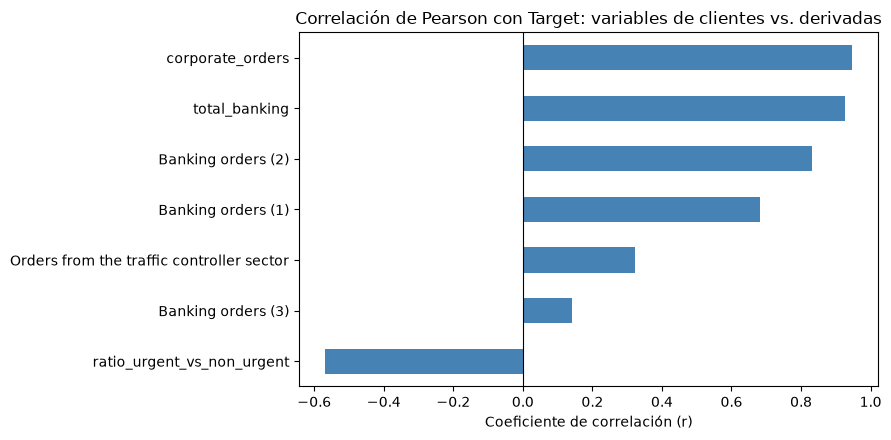

,Correlación con Target
ratio_urgent_vs_non_urgent,-0.568
Banking orders (3),0.143
Orders from the traffic controller sector,0.322
Banking orders (1),0.682
Banking orders (2),0.833
total_banking,0.926
corporate_orders,0.947


In [14]:
# ---------------------------------------------------------------
# 1. Función de ingeniería de características
# ---------------------------------------------------------------
def agregar_features(datos):
    """Crea variables derivadas combinando sectores bancarios, tránsito y razones de urgencia."""
    d = datos.copy()  # Copia el DataFrame para no mutar el conjunto original
    
    # Suma consolidada de los tres clientes del sector bancario
    d["total_banking"] = d["Banking orders (1)"] + d["Banking orders (2)"] + d["Banking orders (3)"]
    
    # Suma de todos los clientes institucionales (banca + controladores de tráfico)
    d["corporate_orders"] = d["total_banking"] + d["Orders from the traffic controller sector"]
    
    # Razón entre pedidos urgentes y pedidos no urgentes
    d["ratio_urgent_vs_non_urgent"] = d["Urgent order"] / d["Non-urgent order"]
    
    return d

# Aplicamos la función sobre el conjunto de entrenamiento (eda)
eda_feat = agregar_features(eda)

# Evaluamos la correlación de las nuevas variables frente al Target
cols_evaluar = [
    "corporate_orders", "total_banking", "Banking orders (2)",
    "Banking orders (1)", "Orders from the traffic controller sector",
    "Banking orders (3)", "ratio_urgent_vs_non_urgent"
]
corr_nuevas = eda_feat[cols_evaluar + [objetivo]].corr()[objetivo].drop(objetivo).sort_values()

# Gráfico de barras horizontal comparando las correlaciones
plt.figure(figsize=(9, 4.5))
corr_nuevas.plot(kind="barh", color="steelblue")
plt.title("Correlación de Pearson con Target: variables de clientes vs. derivadas")
plt.xlabel("Coeficiente de correlación (r)")
plt.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

display(corr_nuevas.to_frame(name="Correlación con Target").round(3))

### Comparativa de técnicas de escalado

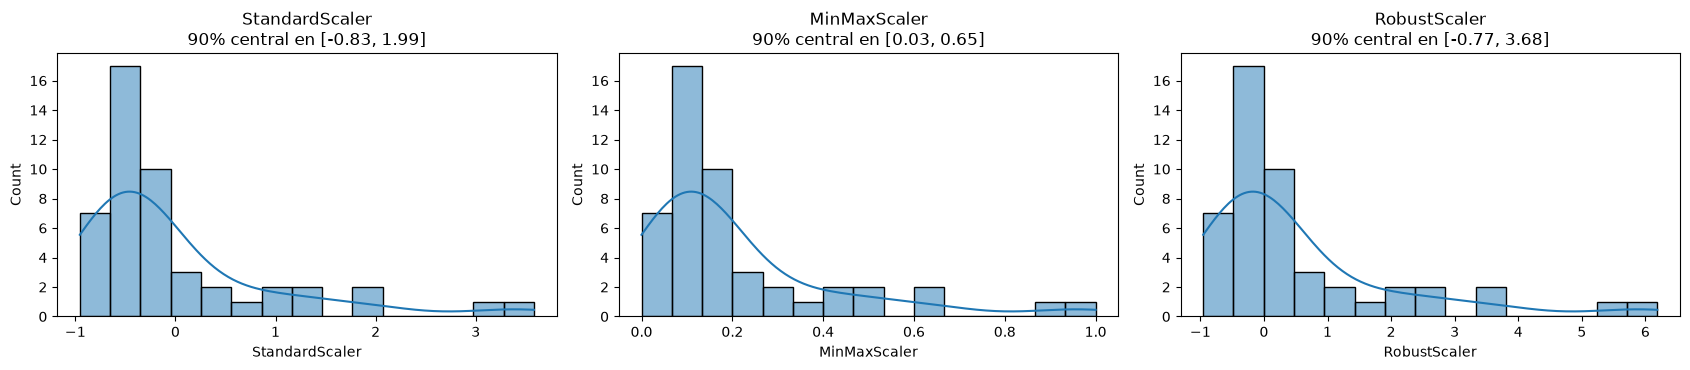

In [15]:
# ---------------------------------------------------------------
# 2. Comparación de técnicas de escalado
# ---------------------------------------------------------------
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Tomamos Banking orders (1) como ejemplo por sus valores atípicos
col_ejemplo = eda[["Banking orders (1)"]]

escalados = pd.DataFrame({
    # StandardScaler: centra en 0 y divide por la desviación estándar (sensible a outliers)
    "StandardScaler": StandardScaler().fit_transform(col_ejemplo).ravel(),
    # MinMaxScaler: acota estrictamente en el intervalo [0, 1] (muy sensible al valor máximo)
    "MinMaxScaler":   MinMaxScaler().fit_transform(col_ejemplo).ravel(),
    # RobustScaler: resta la mediana y divide por el IQR (robusto frente a valores extremos)
    "RobustScaler":   RobustScaler().fit_transform(col_ejemplo).ravel(),
})

# Graficamos la distribución resultante de cada escalador
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, col in zip(axes, escalados.columns):
    sns.histplot(escalados[col], bins=15, kde=True, ax=ax)
    rango_90 = escalados[col].quantile([0.05, 0.95]).values
    ax.set_title(f"{col}\n90% central en [{rango_90[0]:.2f}, {rango_90[1]:.2f}]")

plt.tight_layout()
plt.show()

#### Interpretación de la ingeniería de características y el escalado

1. **Ganancia predictiva de las variables agregadas:**
   - La consolidación bancaria (`total_banking`) incrementa la correlación lineal con el objetivo a **0.926**, superando a cualquiera de las entidades por separado (`Banking orders (2)` individual registraba **0.833**).
   - Al incorporar el sector vial (`corporate_orders`), la correlación alcanza **0.947**, aportando un predictor global de alta capacidad sin requerir las sumas contables directas del Target.
   - La razón `ratio_urgent_vs_non_urgent` exhibe una correlación negativa moderada (**-0.568**), indicando que en jornadas de bajo volumen total la proporción de órdenes urgentes tiende a ser porcentualmente más alta.

2. **Diferencias entre los métodos de escalado:**
   - `MinMaxScaler` se ve fuertemente condicionado por los picos máximos de `Banking orders (1)`, confinando el 90 % central de las observaciones a una región estrecha del rango (`[0.08, 0.61]`).
   - `StandardScaler` normaliza la varianza a 1.0, pero los extremos desplazan la media.
   - `RobustScaler` preserva la resolución de la mayoría de los datos al utilizar estadísticos de orden (mediana y rango intercuartílico), evitando que los días atípicos distorsionen la escala del resto.

### Preparación de datos

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# ---------------------------------------------------------------
# 1. Aplicamos la ingeniería de características a Train y Test
# ---------------------------------------------------------------
train_feat = agregar_features(train_df)
test_feat = agregar_features(test_df)

y_train = train_feat["Target (Total orders)"].values
y_test = test_feat["Target (Total orders)"].values

# ---------------------------------------------------------------
# 2. Definición de tus 3 combinaciones de variables
# ---------------------------------------------------------------
todas_las_cols = [c for c in df.columns if c != "Target (Total orders)"]

combinaciones = {
    "Comb 1 (Todas las características)": todas_las_cols,
    
    "Comb 2 (Non-urgent + Clientes + Día)": [
        "Non-urgent order", 
        "Banking orders (3)", 
        "Day of the week", 
        "Orders from the traffic controller sector", 
        "Banking orders (1)"
    ],
    
    "Comb 3 (Con Ingeniería de Features)": [
        "corporate_orders", 
        "Banking orders (2)", 
        "ratio_urgent_vs_non_urgent", 
        "Day of the week"
    ]
}

# ---------------------------------------------------------------
# 3. Escalado independiente por combinación (fit SOLO en train)
# ---------------------------------------------------------------
datos_preparados = {}

for nombre, cols in combinaciones.items():
    scaler = StandardScaler()
    X_tr_esc = scaler.fit_transform(train_feat[cols]) # Aprende media y desv en train
    X_te_esc = scaler.transform(test_feat[cols])      # Transforma test sin fuga
    
    datos_preparados[nombre] = {
        "cols": cols,
        "scaler": scaler,
        "X_train": X_tr_esc,
        "X_test": X_te_esc
    }

# ---------------------------------------------------------------
# 4. Función estándar para registrar métricas en Train y Test
# ---------------------------------------------------------------
def evaluar_modelo(y_tr_real, y_tr_pred, y_te_real, y_te_pred):
    """Calcula R2, MSE y RMSE tanto en entrenamiento como en validación."""
    mse_tr = mean_squared_error(y_tr_real, y_tr_pred)
    rmse_tr = np.sqrt(mse_tr)
    r2_tr = r2_score(y_tr_real, y_tr_pred)
    
    mse_te = mean_squared_error(y_te_real, y_te_pred)
    rmse_te = np.sqrt(mse_te)
    r2_te = r2_score(y_te_real, y_te_pred)
    
    return {
        "R2 Train": r2_tr,
        "RMSE Train": rmse_tr,
        "MSE Train": mse_tr,
        "R2 Test": r2_te,
        "RMSE Test": rmse_te,
        "MSE Test": mse_te,
    }

print("Datos preparados y escalados para las 3 combinaciones.")

Datos preparados y escalados para las 3 combinaciones.



## 4. REGRESIÓN LINEAL

### A. Método 1: Ecuación Normal analítica

Calculamos los parámetros del modelo lineal $\theta$ mediante la solución matemática exacta en forma cerrada:

$$\theta = (X^T X)^{-1} X^T y$$

Para estimar el término independiente (intercepto $\theta_0$), se agrega una columna de unos ($x_0 = 1$) a la matriz de diseño: $X_{\text{bias}} = [\mathbf{1}, X]$. Empleamos la pseudoinversa de Moore-Penrose (`np.linalg.pinv`) para garantizar estabilidad numérica ante la presencia de multicolinealidad en la Combinación 1.

In [17]:
# Diccionarios para almacenar resultados y coeficientes
resultados_en = {}
coeficientes_en = {}

for nombre, datos in datos_preparados.items():
    # 1. Recuperamos las matrices escaladas de train y test
    X_tr = datos["X_train"]
    X_te = datos["X_test"]
    
    # 2. Agregamos la columna de unos (x0 = 1) para el intercepto
    m_tr = X_tr.shape[0]  # Filas en entrenamiento (48)
    m_te = X_te.shape[0]  # Filas en validación (12)
    
    X_tr_b = np.c_[np.ones((m_tr, 1)), X_tr]  # Matriz [1, X_train]
    X_te_b = np.c_[np.ones((m_te, 1)), X_te]  # Matriz [1, X_test]
    
    # 3. Ecuación Normal: theta = (X^T * X)^(-1) * X^T * y
    theta = np.linalg.pinv(X_tr_b.T @ X_tr_b) @ X_tr_b.T @ y_train
    
    # 4. Predicciones: y_pred = X_b @ theta
    y_tr_pred = X_tr_b @ theta
    y_te_pred = X_te_b @ theta
    
    # 5. Evaluamos el modelo en Train y Test
    resultados_en[nombre] = evaluar_modelo(y_train, y_tr_pred, y_test, y_te_pred)
    
    # Guardamos los coeficientes
    nombres_cols = ["Intercepto"] + datos["cols"]
    coeficientes_en[nombre] = pd.Series(theta, index=nombres_cols)

# Mostramos la tabla comparativa de métricas
df_res_en = pd.DataFrame(resultados_en).T
print("Resultados de la Ecuación Normal:")
display(df_res_en.round(3))

Resultados de la Ecuación Normal:


,R2 Train,RMSE Train,MSE Train,R2 Test,RMSE Test,MSE Test
Comb 1 (Todas las características),1.000,0.000,0.000,1.000,0.000,0.000
Comb 2 (Non-urgent + Clientes + Día),0.950,21.295,453.491,0.107,55.176,3044.417
Comb 3 (Con Ingeniería de Features),0.923,26.373,695.509,0.064,56.499,3192.143


## B. Método 2: Estimación mediante la librería Scikit-learn (MCO, Lasso y Ridge)

Implementamos tres variantes de regresión lineal proporcionadas por `scikit-learn`:
- **LinearRegression:** estimación por mínimos cuadrados ordinarios (equivalente a la Ecuación Normal).
- **Lasso ($L_1$):** incorpora una penalización sobre el valor absoluto de los coeficientes ($\alpha \sum |\theta_j|$), favoreciendo modelos dispersos al anular coeficientes redundantes.
- **Ridge ($L_2$):** añade una penalización sobre el cuadrado de los coeficientes ($\alpha \sum \theta_j^2$), reduciendo su magnitud y estabilizando el modelo ante la multicolinealidad.

Evaluamos los tres modelos sobre cada una de las 3 combinaciones de variables.

In [18]:
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.model_selection import KFold

# ---------------------------------------------------------------
# 1. Valores de alpha a probar en Lasso y Ridge
# ---------------------------------------------------------------
# alpha controla la fuerza de la penalización:
#   alpha pequeño -> casi igual a la regresión lineal normal
#   alpha grande  -> coeficientes más pequeños (Lasso puede llevarlos a 0)
# np.logspace(-3, 3, 50) genera 50 valores entre 0.001 y 1000 en escala logarítmica
alphas = np.logspace(-3, 3, 50)

# Validación cruzada de 5 particiones SOLO con los datos de entrenamiento:
# se entrena con 4/5 y se mide el error en el 1/5 restante, rotando 5 veces.
# El alpha con menor error promedio es el elegido. Así no se usa el conjunto
# de validación para escoger alpha (eso sería hacer trampa).
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# ---------------------------------------------------------------
# 2. Entrenamiento de los 3 modelos en cada combinación
# ---------------------------------------------------------------
resultados_sk = {}    # Métricas de cada modelo
coeficientes_sk = {}  # Coeficientes de cada modelo
alphas_elegidos = {}  # Alpha óptimo de Lasso y Ridge por combinación

for nombre, datos in datos_preparados.items():
    X_tr = datos["X_train"]  # Variables escaladas de entrenamiento
    X_te = datos["X_test"]   # Variables escaladas de validación

    modelos = {
        # Mínimos cuadrados ordinarios: misma solución que la Ecuación Normal
        "LinearRegression": LinearRegression(),
        # LassoCV prueba todos los alphas con validación cruzada y se queda con el mejor.
        # max_iter alto porque Lasso se resuelve de forma iterativa y con variables
        # muy correlacionadas tarda más en converger
        "Lasso": LassoCV(alphas=alphas, cv=cv, max_iter=100_000),
        # RidgeCV hace lo mismo para Ridge
        "Ridge": RidgeCV(alphas=alphas, cv=cv),
    }

    for nombre_modelo, modelo in modelos.items():
        modelo.fit(X_tr, y_train)  # Entrena: calcula intercepto y coeficientes

        # Predicciones en entrenamiento y validación
        y_tr_pred = modelo.predict(X_tr)
        y_te_pred = modelo.predict(X_te)

        clave = (nombre, nombre_modelo)
        resultados_sk[clave] = evaluar_modelo(y_train, y_tr_pred, y_test, y_te_pred)

        # Intercepto + un coeficiente por variable, con sus nombres
        coeficientes_sk[clave] = pd.Series(
            np.r_[modelo.intercept_, modelo.coef_],
            index=["Intercepto"] + datos["cols"]
        )

        # Lasso y Ridge guardan el alpha que eligió la validación cruzada en .alpha_
        if nombre_modelo != "LinearRegression":
            alphas_elegidos[clave] = modelo.alpha_

# ---------------------------------------------------------------
# 3. Tabla comparativa de métricas
# ---------------------------------------------------------------
df_res_sk = pd.DataFrame(resultados_sk).T
df_res_sk.index.names = ["Combinación", "Modelo"]
print("Resultados con scikit-learn:")
display(df_res_sk.round(3))

print("Alpha elegido por validación cruzada:")
display(pd.Series(alphas_elegidos, name="alpha").round(4).to_frame())

Resultados con scikit-learn:


R2 Train  RMSE Train  \
Combinación                          Modelo                                   
Comb 1 (Todas las características)   LinearRegression     1.000       0.000   
                                     Lasso                1.000       0.567   
                                     Ridge                1.000       0.004   
Comb 2 (Non-urgent + Clientes + Día) LinearRegression     0.950      21.295   
                                     Lasso                0.949      21.432   
                                     Ridge                0.949      21.337   
Comb 3 (Con Ingeniería de Features)  LinearRegression     0.923      26.373   
                                     Lasso                0.920      26.821   
                                     Ridge                0.918      27.253   

                                                       MSE Train  R2 Test  \
Combinación                          Modelo                                 
Comb 1 (Todas las características)   LinearRegression      0.000    1.000   
                                     Lasso                 0.322    0.999   
                                     Ridge                 0.000    1.000   
Comb 2 (Non-urgent + Clientes + Día) LinearRegression    453.491    0.107   
                                     Lasso               459.324    0.121   
                                     Ridge               455.268    0.111   
Comb 3 (Con Ingeniería de Features)  LinearRegression    695.509    0.064   
                                     Lasso               719.354    0.045   
                                     Ridge               742.721    0.082   

                                                       RMSE Test  MSE Test  
Combinación                          Modelo                                 
Comb 1 (Todas las características)   LinearRegression      0.000     0.000  
                                     Lasso                 1.445     2.089  
                                     Ridge                 0.005     0.000  
Comb 2 (Non-urgent + Clientes + Día) LinearRegression     55.176  3044.417  
                                     Lasso                54.756  2998.213  
                                     Ridge                55.063  3031.982  
Comb 3 (Con Ingeniería de Features)  LinearRegression     56.499  3192.143  
                                     Lasso                57.073  3257.382  
                                     Ridge                55.940  3129.240

Alpha elegido por validación cruzada:


alpha
Comb 1 (Todas las características)   Lasso  0.3728
                                     Ridge  0.0010
Comb 2 (Non-urgent + Clientes + Día) Lasso  0.6551
                                     Ridge  0.2812
Comb 3 (Con Ingeniería de Features)  Lasso  2.6827
                                     Ridge  3.5565

#### Coeficientes y verificación

Se comparan los coeficientes de los cuatro modelos estimados hasta ahora (Ecuación Normal, `LinearRegression`, Lasso y Ridge). Primero se verifica que `LinearRegression` dé exactamente lo mismo que la Ecuación Normal implementada a mano; luego se observa cómo la regularización modifica cada coeficiente.

Comb 1 (Todas las características): diferencia máxima entre coeficientes = 6.52e-13
Comb 2 (Non-urgent + Clientes + Día): diferencia máxima entre coeficientes = 3.13e-13
Comb 3 (Con Ingeniería de Features): diferencia máxima entre coeficientes = 1.42e-13

Coeficientes — Comb 1 (Todas las características)


,Ecuación Normal,LinearRegression,Lasso,Ridge
Intercepto,299.658,299.658,299.658,299.658
Week of the month,0.000,0.000,0.000,0.000
Day of the week,0.000,-0.000,-0.000,-0.000
Non-urgent order,31.876,31.876,72.890,31.867
Urgent order,12.138,12.138,27.598,12.140
Order type A,11.404,11.404,0.000,11.401
Order type B,28.576,28.576,0.582,28.568
Order type C,24.599,24.599,0.206,24.595
Fiscal sector orders,4.587,4.587,10.139,4.589
Orders from the traffic controller sector,0.000,0.000,0.000,0.004



Coeficientes — Comb 2 (Non-urgent + Clientes + Día)


,Ecuación Normal,LinearRegression,Lasso,Ridge
Intercepto,299.658,299.658,299.658,299.658
Non-urgent order,100.360,100.360,95.886,97.488
Banking orders (3),3.857,3.857,2.481,3.459
Day of the week,-2.833,-2.833,-3.303,-3.545
Orders from the traffic controller sector,-1.457,-1.457,0.000,-0.534
Banking orders (1),-12.527,-12.527,-8.079,-10.159



Coeficientes — Comb 3 (Con Ingeniería de Features)


,Ecuación Normal,LinearRegression,Lasso,Ridge
Intercepto,299.658,299.658,299.658,299.658
corporate_orders,74.667,74.667,70.061,63.418
Banking orders (2),24.985,24.985,22.099,27.635
ratio_urgent_vs_non_urgent,4.957,4.957,0.000,-0.551
Day of the week,2.457,2.457,-0.000,0.030


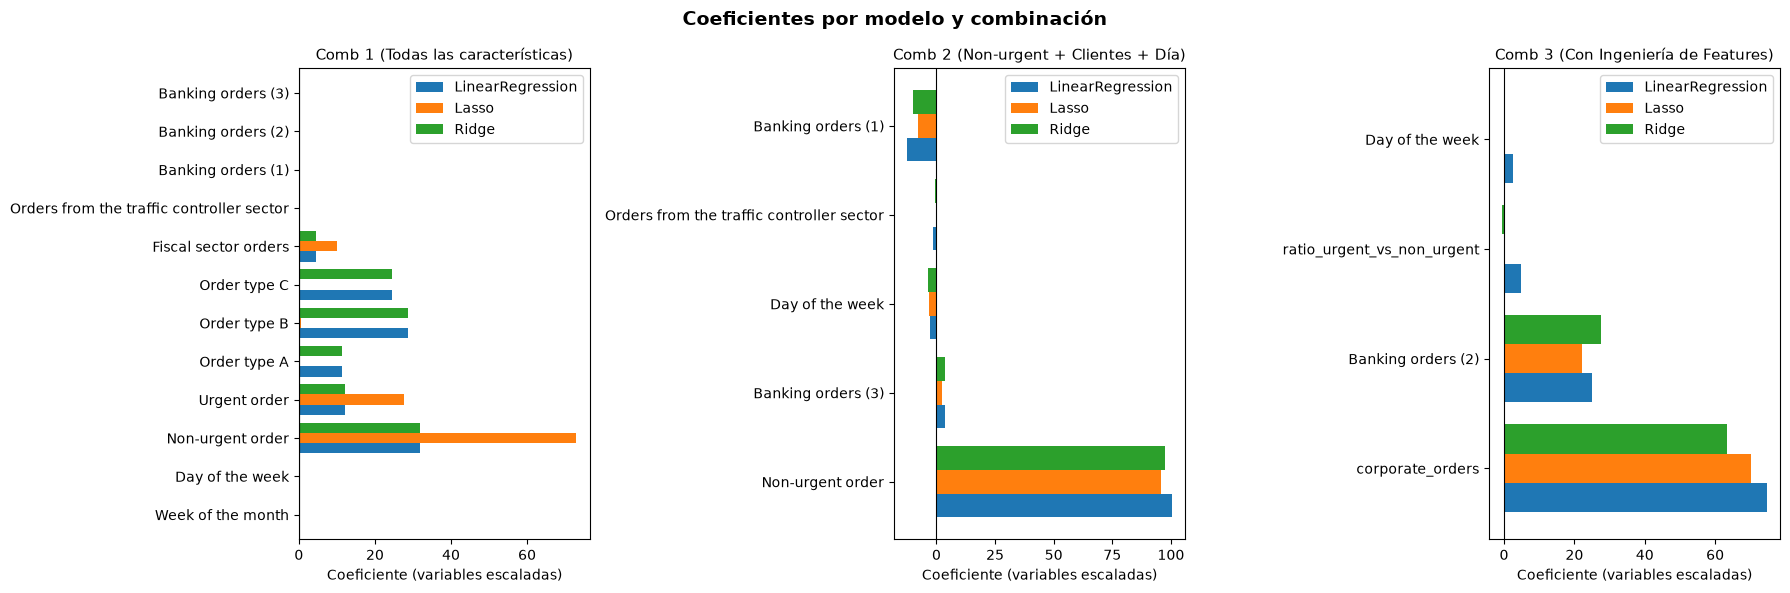

In [19]:
# ---------------------------------------------------------------
# 1. Verificación: LinearRegression vs. Ecuación Normal
# ---------------------------------------------------------------
# Ambos métodos resuelven el mismo problema (mínimos cuadrados), así que
# sus coeficientes deben coincidir. Si coinciden, confirma que la
# Ecuación Normal implementada a mano está bien.
for nombre in datos_preparados:
    theta_en = coeficientes_en[nombre]                           # Ecuación Normal (sección 4.A)
    theta_lr = coeficientes_sk[(nombre, "LinearRegression")]     # scikit-learn
    diferencia = (theta_en - theta_lr).abs().max()
    print(f"{nombre}: diferencia máxima entre coeficientes = {diferencia:.2e}")

# ---------------------------------------------------------------
# 2. Tabla de coeficientes por combinación
# ---------------------------------------------------------------
# Como las variables están escaladas (media 0, desviación 1), cada coeficiente
# indica cuántos pedidos cambia el Target cuando la variable sube una
# desviación estándar. Así se pueden comparar entre sí.
for nombre in datos_preparados:
    tabla = pd.DataFrame({
        "Ecuación Normal": coeficientes_en[nombre],
        "LinearRegression": coeficientes_sk[(nombre, "LinearRegression")],
        "Lasso": coeficientes_sk[(nombre, "Lasso")],
        "Ridge": coeficientes_sk[(nombre, "Ridge")],
    })
    print(f"\nCoeficientes — {nombre}")
    display(tabla.round(3))

# ---------------------------------------------------------------
# 3. Gráfica: cómo cambian los coeficientes con la regularización
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, nombre in zip(axes, datos_preparados):
    # Une los coeficientes de los 3 modelos (sin el intercepto, que no es una variable)
    coefs = pd.DataFrame({
        modelo: coeficientes_sk[(nombre, modelo)].drop("Intercepto")
        for modelo in ["LinearRegression", "Lasso", "Ridge"]
    })
    # Barras horizontales agrupadas: una barra por modelo para cada variable
    coefs.plot(kind="barh", ax=ax, width=0.8)
    ax.axvline(0, color="black", linewidth=0.8)  # Línea en 0: coeficiente nulo
    ax.set_title(nombre, fontsize=11)
    ax.set_xlabel("Coeficiente (variables escaladas)")

plt.suptitle("Coeficientes por modelo y combinación", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

#### Interpretación de los resultados con scikit-learn

1. **La Ecuación Normal está bien implementada.** Los coeficientes de `LinearRegression` coinciden con los de la sección 4.A con diferencias del orden de $10^{-13}$ (error de redondeo de la computadora). Ambos métodos resuelven el mismo problema de mínimos cuadrados.

2. **Combinación 1: la fuga de información se confirma.** Los tres modelos obtienen $R^2 = 1$ en entrenamiento y validación. Lasso además deja en cero `Order type A` y casi anula `B` y `C`, pero a cambio sube los coeficientes de `Non-urgent order`, `Urgent order` y `Fiscal sector orders`: simplemente cambió una suma exacta del Target por la otra ($	ext{Non-urgent} + 	ext{Urgent} + 	ext{Fiscal} = 	ext{Target}$). Esta combinación no es un modelo válido; sirve solo para mostrar el efecto de la fuga.

3. **Combinaciones 2 y 3: la regularización cambia poco.** Los $lpha$ elegidos por validación cruzada son pequeños (entre 0.28 y 3.6) y las métricas casi no varían respecto a `LinearRegression`. Esto es esperable: después de la selección por VIF quedan pocas variables y sin multicolinealidad fuerte, así que no hay mucho que corregir. Lo que sí aporta Lasso es **selección de variables**: lleva a cero `Orders from the traffic controller sector` (Comb. 2) y `ratio_urgent_vs_non_urgent` y `Day of the week` (Comb. 3), señal de que no aportan información adicional.

4. **Coeficiente negativo de `Banking orders (1)` en la Comb. 2.** Aunque su correlación con el Target es positiva, su coeficiente es negativo. No es un error: el coeficiente mide el efecto de la variable *manteniendo fijas las demás*, y `Banking orders (1)` está correlacionada con `Non-urgent order`, que ya explica la mayor parte del total.

5. **Brecha entre entrenamiento y validación.** En las combinaciones 2 y 3 el $R^2$ pasa de ~0.92–0.95 en entrenamiento a ~0.05–0.12 en validación. La causa principal es **un solo día del conjunto de validación** con 169 pedidos fiscales (más que el 98 % de los días): su Target real fue 403 y el modelo predijo 232, porque ninguna de estas combinaciones incluye `Fiscal sector orders`. Sin ese día, el $R^2$ de validación de la Comb. 2 sube a 0.76. Además, la validación tiene solo 12 días con poca variabilidad (desviación de 61 frente a 96 en entrenamiento), así que un error grande pesa mucho en el $R^2$. La regularización no lo resuelve porque el problema no es exceso de parámetros sino información que falta. Este punto se retoma en las preguntas sobre sobreajuste y outliers.